# Thực nghiệm Support Vector Machine (SVM)

## Mini Capstone Machine Learning

Notebook này phụ trách **SVM** trong dự án so sánh ba thuật toán (SVM, KNN, Decision Tree). Mô hình dùng dữ liệu sạch và train/test split cố định từ notebook 02. Siêu tham số được chọn bằng 5-fold cross-validation trên tập train theo **F1-macro**; tập test chỉ dùng để đánh giá cấu hình SVM tốt nhất **một lần cuối**.

Cấu trúc và quy ước hoàn toàn đồng bộ với notebook `03_knn.ipynb` để đảm bảo so sánh công bằng.

## 1. SVM và các siêu tham số

SVM tìm siêu phẳng phân tách hai lớp với lề lớn nhất. Với dữ liệu không gian cao và số mẫu vừa phải như Breast Cancer Wisconsin, SVM thường cho kết quả rất tốt khi được chuẩn hóa đúng.

Vì khoảng cách và biên quyết định nhạy với thang đo, **`StandardScaler` bắt buộc phải nằm trong pipeline**.

### Siêu tham số thử nghiệm

- `kernel`: `linear`, `rbf`
- `C`: `0.1`, `1`, `10`, `100`
- `gamma`: `scale`, `auto`, `0.001`, `0.01`, `0.1` (chỉ có ý nghĩa với kernel `rbf`)

Tổng cộng **24 cấu hình**. Cấu hình được chọn theo **F1-macro trung bình qua cross-validation**. Recall của lớp ác tính `M` được theo dõi để hỗ trợ nhận xét rủi ro bỏ sót ca ác tính.

**Lưu ý:** `probability=True` được bật để tính ROC-AUC.

In [4]:
from pathlib import Path
import hashlib
import json
import time

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

sns.set_theme(style='whitegrid', palette='Set2')
RANDOM_STATE = 42
CV_FOLDS = 5
GRID_SEARCH_N_JOBS = 1

project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent

clean_data_path = project_root / 'data' / 'processed' / 'breast_cancer_clean.csv'
splits_dir = project_root / 'data' / 'splits'
train_indices_path = splits_dir / 'train_indices.csv'
test_indices_path = splits_dir / 'test_indices.csv'
metadata_path = splits_dir / 'split_metadata.json'
output_dir = project_root / 'outputs' / 'svm'

required_paths = [clean_data_path, train_indices_path, test_indices_path, metadata_path]
missing_paths = [str(path) for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError('Thiếu file cần thiết:\n' + '\n'.join(missing_paths))

print(f'Dữ liệu sạch: {clean_data_path}')
print(f'Split dùng chung: {splits_dir}')
print(f'Kết quả SVM sẽ lưu tại: {output_dir}')

Dữ liệu sạch: C:\Users\Khoa\Downloads\AIL303m-Breast-Cancer-Classification-main (1)\AIL303m-Breast-Cancer-Classification-main\data\processed\breast_cancer_clean.csv
Split dùng chung: C:\Users\Khoa\Downloads\AIL303m-Breast-Cancer-Classification-main (1)\AIL303m-Breast-Cancer-Classification-main\data\splits
Kết quả SVM sẽ lưu tại: C:\Users\Khoa\Downloads\AIL303m-Breast-Cancer-Classification-main (1)\AIL303m-Breast-Cancer-Classification-main\outputs\svm


## 2. Kiểm tra tính nhất quán của dữ liệu và split

Notebook kiểm tra SHA-256 của file sạch với metadata do notebook 02 tạo. Nếu dữ liệu đã thay đổi hoặc thứ tự dòng bị đảo, quá trình dừng để tránh dùng sai index train/test.

In [5]:
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as file:
        for chunk in iter(lambda: file.read(8192), b''):
            digest.update(chunk)
    return digest.hexdigest()

metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
current_sha256 = sha256_file(clean_data_path)
if current_sha256 != metadata['source_sha256']:
    raise ValueError(
        'Dữ liệu sạch đã thay đổi sau khi tạo split. Không thể bảo đảm train/test index còn đúng.'
    )

data = pd.read_csv(clean_data_path)
train_indices = pd.read_csv(train_indices_path)['row_index'].astype(int).tolist()
test_indices = pd.read_csv(test_indices_path)['row_index'].astype(int).tolist()

if len(data) != metadata['total_rows']:
    raise ValueError('Số dòng dữ liệu không trùng metadata của split.')
if set(train_indices).intersection(test_indices):
    raise ValueError('Train và test có index trùng nhau.')
if len(train_indices) != metadata['train_rows'] or len(test_indices) != metadata['test_rows']:
    raise ValueError('Kích thước train/test không trùng metadata.')
if min(train_indices + test_indices) < 0 or max(train_indices + test_indices) >= len(data):
    raise ValueError('Có row_index nằm ngoài phạm vi dữ liệu.')

print('Dữ liệu và split hợp lệ.')
print(f'SHA-256: {current_sha256}')
print(f'Tổng số mẫu: {len(data)} | Train: {len(train_indices)} | Test: {len(test_indices)}')

Dữ liệu và split hợp lệ.
SHA-256: f6c65a8089f4dffb414973265861e4040ce6088473cba0b4552357f928995459
Tổng số mẫu: 569 | Train: 455 | Test: 114


## 3. Tạo train/test theo index cố định

Notebook này **không** gọi lại hàm chia dữ liệu. Toàn bộ 30 đặc trưng được giữ lại; `diagnosis` được mã hóa `B=0`, `M=1`.

In [6]:
train_data = data.iloc[train_indices].copy()
test_data = data.iloc[test_indices].copy()

feature_columns = [column for column in data.columns if column != 'diagnosis']
X_train = train_data[feature_columns]
X_test = test_data[feature_columns]
y_train = train_data['diagnosis'].map({'B': 0, 'M': 1})
y_test = test_data['diagnosis'].map({'B': 0, 'M': 1})

print(f'X_train: {X_train.shape}; X_test: {X_test.shape}')
print(f'Số đặc trưng: {len(feature_columns)}')
display(pd.DataFrame({
    'train': train_data['diagnosis'].value_counts(),
    'test': test_data['diagnosis'].value_counts(),
}).fillna(0).astype(int))

X_train: (455, 30); X_test: (114, 30)
Số đặc trưng: 30


,train,test
diagnosis,,
B,285,72
M,170,42


## 4. Baseline SVM

Baseline được đặt trước khi tuning: kernel `rbf`, `C=1.0`, `gamma='scale'`. Baseline chỉ được đánh giá bằng cross-validation trên train để làm mốc so sánh với SVM sau tuning.

In [8]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    'f1_macro': 'f1_macro',
    'accuracy': 'accuracy',
    'recall_malignant': make_scorer(recall_score, pos_label=1),
}

baseline_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(
        kernel='rbf',
        C=1.0,
        gamma='scale',
        probability=True,
        random_state=RANDOM_STATE,
    )),
])

baseline_cv = cross_validate(
    baseline_pipeline, X_train, y_train,
    cv=cv, scoring=scoring, return_train_score=False
)

baseline_summary = {
    metric: {
        'mean': float(baseline_cv[f'test_{metric}'].mean()),
        'std' : float(baseline_cv[f'test_{metric}'].std()),
    }
    for metric in scoring
}

# Hiển thị bảng không dùng .style để tránh lỗi thiếu jinja2
baseline_df = pd.DataFrame(baseline_summary).T.rename(
    columns={'mean': 'trung_binh_cv', 'std': 'do_lech_chuan_cv'}
)
display(baseline_df.round(4))

c:\Users\Khoa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Khoa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Khoa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Khoa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_bas

,trung_binh_cv,do_lech_chuan_cv
f1_macro,0.9693,0.0160
accuracy,0.9714,0.0149
recall_malignant,0.9529,0.0300


## 5. Tuning siêu tham số SVM bằng GridSearchCV

GridSearchCV sử dụng cùng 5-fold StratifiedKFold. `f1_macro` là tiêu chí `refit`. Accuracy và Recall M chỉ là chỉ số bổ sung để phân tích, **không** thay đổi quy tắc chọn mô hình.

Pipeline luôn gồm `StandardScaler` → `SVC(probability=True)` để bảo đảm không có data leakage và có thể tính ROC-AUC.

In [10]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(probability=True, random_state=RANDOM_STATE)),
])

parameter_grid = [
    {
        'svm__kernel': ['linear'],
        'svm__C': [0.1, 1, 10, 100],
    },
    {
        'svm__kernel': ['rbf'],
        'svm__C': [0.1, 1, 10, 100],
        'svm__gamma': ['scale', 'auto', 0.001, 0.01, 0.1],
    },
]

svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=parameter_grid,
    scoring=scoring,
    refit='f1_macro',
    cv=cv,
    return_train_score=False,
    n_jobs=GRID_SEARCH_N_JOBS,
    verbose=1,          # giảm từ 2 xuống 1 cho gọn
)

tuning_start = time.perf_counter()
svm_search.fit(X_train, y_train)
tuning_seconds = time.perf_counter() - tuning_start

print(f'Số cấu hình đã thử : {len(svm_search.cv_results_["params"])}')
print(f'Thời gian tuning   : {tuning_seconds:.2f} giây')
print(f'Best parameters    : {svm_search.best_params_}')
print(f'Best F1-macro (CV) : {svm_search.best_score_:.4f}')

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Số cấu hình đã thử : 24
Thời gian tuning   : 7.34 giây
Best parameters    : {'svm__C': 0.1, 'svm__kernel': 'linear'}
Best F1-macro (CV) : 0.9763


### 5.1. Bảng Top 10 cấu hình

Bảng được xếp theo rank F1-macro CV. Chênh lệch nhỏ hơn độ lệch chuẩn CV cần được diễn giải thận trọng.

In [14]:
cv_results = pd.DataFrame(svm_search.cv_results_)

tuning_summary = pd.DataFrame({
    'rank_f1_macro'           : cv_results['rank_test_f1_macro'],
    'kernel'                  : cv_results['param_svm__kernel'].astype(str),
    'C'                       : cv_results['param_svm__C'].astype(float),
    'gamma'                   : cv_results['param_svm__gamma'].astype(str),
    'mean_f1_macro_cv'        : cv_results['mean_test_f1_macro'],
    'std_f1_macro_cv'         : cv_results['std_test_f1_macro'],
    'mean_recall_malignant_cv': cv_results['mean_test_recall_malignant'],
    'mean_accuracy_cv'        : cv_results['mean_test_accuracy'],
}).sort_values(['rank_f1_macro', 'C']).reset_index(drop=True)

# Với kernel linear, gamma không có ý nghĩa → hiển thị "-"
tuning_summary['gamma'] = tuning_summary['gamma'].replace({'nan': '-', 'None': '-'})

top_10_configurations = tuning_summary.head(10)

# Hiển thị bảng không dùng .style để tránh lỗi thiếu jinja2
display(top_10_configurations.round({
    'mean_f1_macro_cv'        : 4,
    'std_f1_macro_cv'         : 4,
    'mean_recall_malignant_cv': 4,
    'mean_accuracy_cv'        : 4,
    'C'                       : 1,
}))

,rank_f1_macro,kernel,C,gamma,mean_f1_macro_cv,std_f1_macro_cv,mean_recall_malignant_cv,mean_accuracy_cv
0,1,linear,0.1,NaN,0.9763,0.0001,0.9529,0.9780
1,2,rbf,10.0,0.01,0.9763,0.0107,0.9529,0.9780
2,3,rbf,100.0,0.01,0.9762,0.0214,0.9529,0.9780
3,4,rbf,10.0,scale,0.9741,0.0228,0.9588,0.9758
4,4,rbf,10.0,auto,0.9741,0.0228,0.9588,0.9758
5,6,rbf,100.0,0.001,0.9739,0.0049,0.9471,0.9758
6,7,linear,1.0,NaN,0.9716,0.0122,0.9529,0.9736
7,8,rbf,1.0,scale,0.9693,0.0160,0.9529,0.9714
8,8,rbf,1.0,auto,0.9693,0.0160,0.9529,0.9714
9,10,rbf,1.0,0.01,0.9689,0.0166,0.9294,0.9714


### 5.2. Ảnh hưởng của C theo từng kernel

Biểu đồ thể hiện Mean F1-macro CV theo giá trị C, tách theo kernel. Error bar là độ lệch chuẩn qua 5 folds.

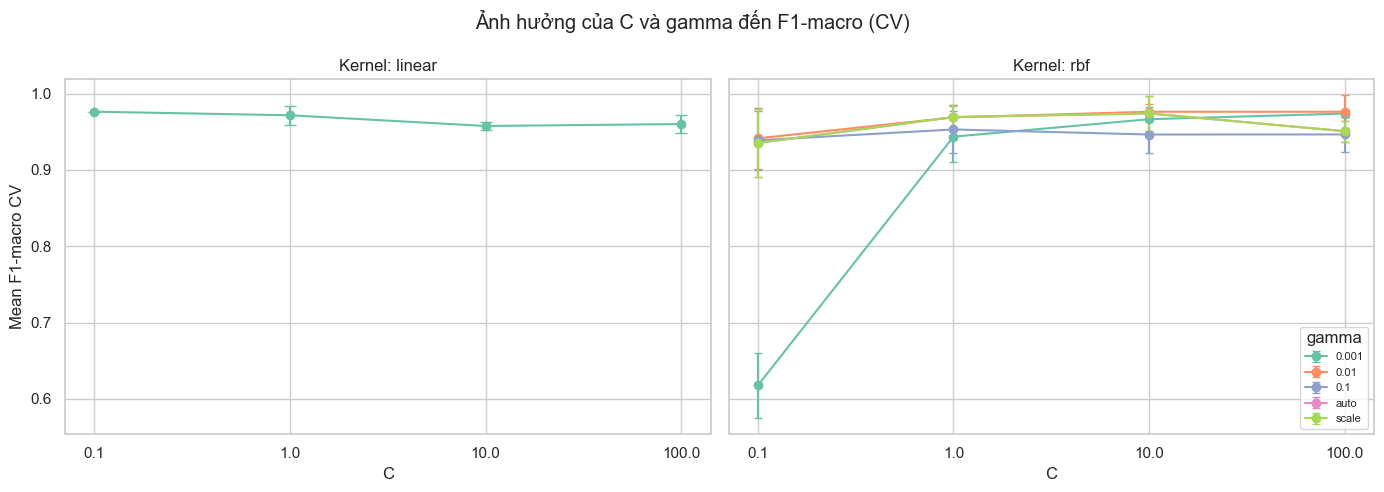

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

linear_results = tuning_summary[tuning_summary['kernel'] == 'linear'].sort_values('C')
axes[0].errorbar(
    linear_results['C'],
    linear_results['mean_f1_macro_cv'],
    yerr=linear_results['std_f1_macro_cv'],
    marker='o',
    capsize=4,
    color='C0',
)
axes[0].set_title('Kernel: linear')
axes[0].set_xlabel('C')
axes[0].set_xscale('log')
axes[0].set_ylabel('Mean F1-macro CV')
axes[0].set_xticks([0.1, 1, 10, 100])
axes[0].get_xaxis().set_major_formatter(plt.ScalarFormatter())

rbf_results = tuning_summary[tuning_summary['kernel'] == 'rbf']
for gamma_name, group in rbf_results.groupby('gamma'):
    group = group.sort_values('C')
    axes[1].errorbar(
        group['C'],
        group['mean_f1_macro_cv'],
        yerr=group['std_f1_macro_cv'],
        marker='o',
        capsize=3,
        label=str(gamma_name),
    )
axes[1].set_title('Kernel: rbf')
axes[1].set_xlabel('C')
axes[1].set_xscale('log')
axes[1].set_xticks([0.1, 1, 10, 100])
axes[1].get_xaxis().set_major_formatter(plt.ScalarFormatter())
axes[1].legend(title='gamma', fontsize=8)

fig.suptitle('Ảnh hưởng của C và gamma đến F1-macro (CV)')
fig.tight_layout()
output_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(output_dir / 'line_chart_C_f1_macro.png', dpi=200, bbox_inches='tight')
plt.show()

### 5.3. Heatmap cấu hình RBF (C × gamma)

Heatmap chỉ áp dụng cho kernel RBF. Giá trị/màu là Mean F1-macro CV.

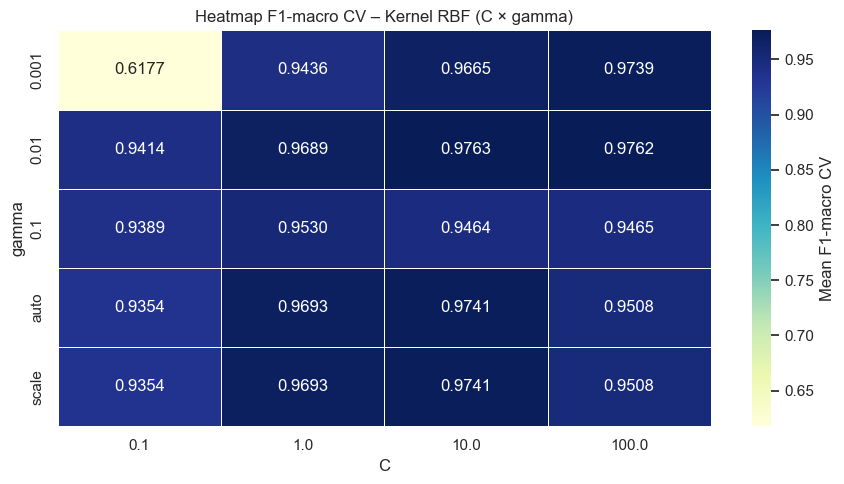

In [13]:
rbf_only = tuning_summary[tuning_summary['kernel'] == 'rbf'].copy()
heatmap_data = rbf_only.pivot(index='gamma', columns='C', values='mean_f1_macro_cv')

gamma_order = ['0.001', '0.01', '0.1', 'auto', 'scale']
heatmap_data = heatmap_data.reindex([g for g in gamma_order if g in heatmap_data.index])

plt.figure(figsize=(9, 5))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.4f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Mean F1-macro CV'},
)
plt.title('Heatmap F1-macro CV – Kernel RBF (C × gamma)')
plt.xlabel('C')
plt.ylabel('gamma')
plt.tight_layout()
plt.savefig(output_dir / 'heatmap_rbf_C_gamma.png', dpi=200, bbox_inches='tight')
plt.show()

### 5.4. Scatter plot: F1-macro và Recall lớp ác tính

Biểu đồ này giúp kiểm tra trade-off giữa F1-macro và Recall M.

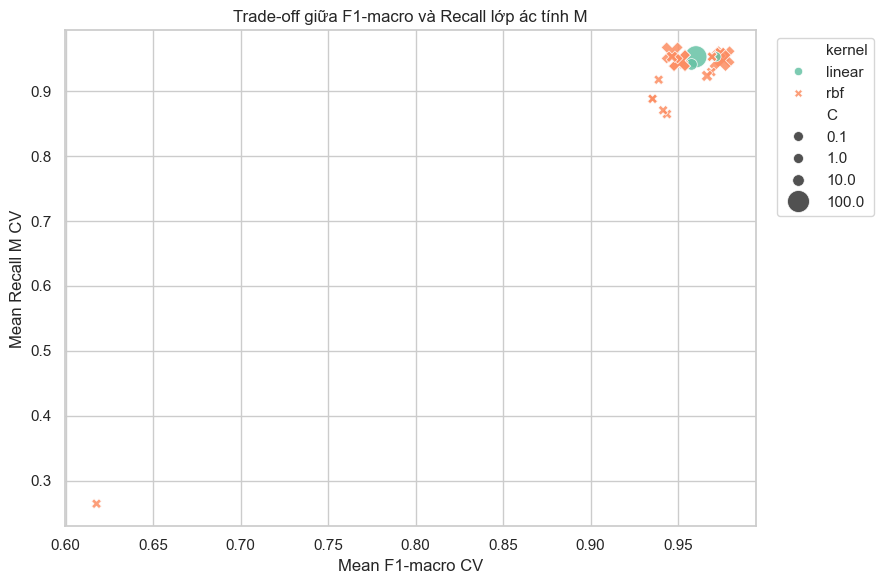

In [15]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=tuning_summary,
    x='mean_f1_macro_cv',
    y='mean_recall_malignant_cv',
    hue='kernel',
    style='kernel',
    size='C',
    sizes=(50, 250),
    alpha=0.85,
)
plt.xlabel('Mean F1-macro CV')
plt.ylabel('Mean Recall M CV')
plt.title('Trade-off giữa F1-macro và Recall lớp ác tính M')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(output_dir / 'scatter_f1_vs_recall_malignant.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Đánh giá SVM tốt nhất trên tập test độc lập

Cell này chỉ chạy sau khi GridSearchCV đã chốt cấu hình theo F1-macro CV. **Không** dùng kết quả test để quay lại chọn lại siêu tham số.

In [17]:
best_svm = svm_search.best_estimator_

prediction_start = time.perf_counter()
y_pred = best_svm.predict(X_test)
y_probability_m = best_svm.predict_proba(X_test)[:, 1]
prediction_seconds = time.perf_counter() - prediction_start

test_metrics = {
    'accuracy'               : float(accuracy_score(y_test, y_pred)),
    'precision_malignant'    : float(precision_score(y_test, y_pred, pos_label=1, zero_division=0)),
    'recall_malignant'       : float(recall_score(y_test, y_pred, pos_label=1, zero_division=0)),
    'f1_malignant'           : float(f1_score(y_test, y_pred, pos_label=1, zero_division=0)),
    'f1_macro'               : float(f1_score(y_test, y_pred, average='macro', zero_division=0)),
    'roc_auc'                : float(roc_auc_score(y_test, y_probability_m)),
    'tuning_seconds'         : float(tuning_seconds),
    'test_prediction_seconds': float(prediction_seconds),
}

# Hiển thị bảng không dùng .style
test_metrics_df = pd.DataFrame([test_metrics]).T.rename(columns={0: 'gia_tri'})
display(test_metrics_df.round(4))

print('Best parameters :', svm_search.best_params_)
print(f'Best CV F1-macro: {svm_search.best_score_:.4f}')

,gia_tri
accuracy,0.9825
precision_malignant,1.0000
recall_malignant,0.9524
f1_malignant,0.9756
f1_macro,0.9810
roc_auc,0.9964
tuning_seconds,7.3390
test_prediction_seconds,0.0219


Best parameters : {'svm__C': 0.1, 'svm__kernel': 'linear'}
Best CV F1-macro: 0.9763


### 6.1. Confusion matrix và ROC curve

Confusion matrix cho biết số mẫu lành/ác tính dự đoán đúng và sai. ROC curve sử dụng xác suất lớp M.

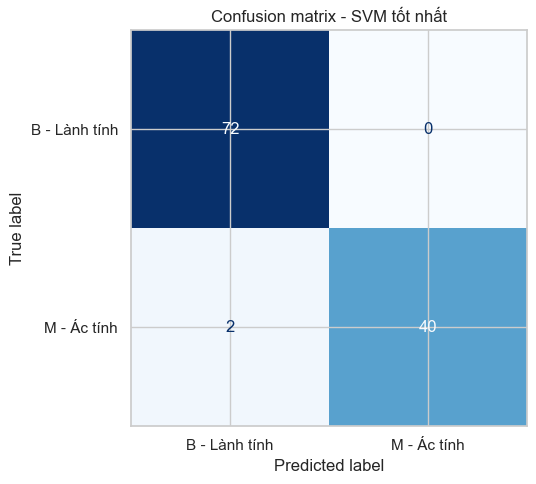

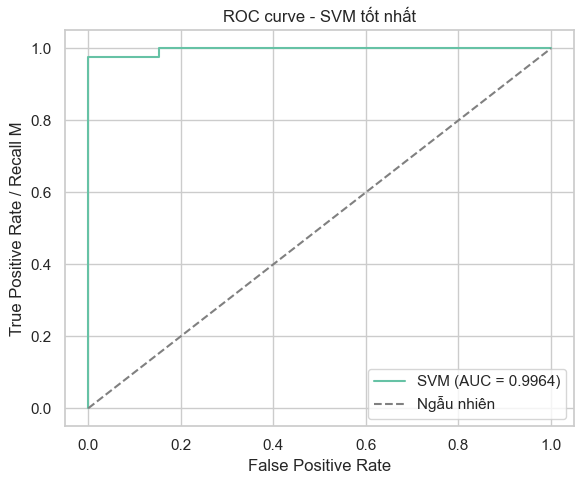

In [18]:
fig, axis = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['B - Lành tính', 'M - Ác tính'],
    cmap='Blues',
    colorbar=False,
    ax=axis,
)
axis.set_title('Confusion matrix - SVM tốt nhất')
fig.tight_layout()
fig.savefig(output_dir / 'confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

false_positive_rate, true_positive_rate, _ = roc_curve(y_test, y_probability_m)
plt.figure(figsize=(6, 5))
plt.plot(false_positive_rate, true_positive_rate, label=f'SVM (AUC = {test_metrics["roc_auc"]:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Ngẫu nhiên')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate / Recall M')
plt.title('ROC curve - SVM tốt nhất')
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / 'roc_curve.png', dpi=200, bbox_inches='tight')
plt.show()

## 7. Lưu số liệu cho notebook tổng hợp

Các file trong `outputs/svm/` là dữ liệu đầu vào của notebook 06. Chỉ sau khi đã lưu các file này, nhóm mới dùng số liệu SVM để so sánh với KNN và Decision Tree.

In [19]:
output_dir.mkdir(parents=True, exist_ok=True)

best_params_serializable = {
    k: (float(v) if isinstance(v, (int, float)) else v)
    for k, v in svm_search.best_params_.items()
}

(output_dir / 'best_parameters.json').write_text(
    json.dumps(best_params_serializable, ensure_ascii=False, indent=2), encoding='utf-8'
)
(output_dir / 'baseline_cv_metrics.json').write_text(
    json.dumps(baseline_summary, ensure_ascii=False, indent=2), encoding='utf-8'
)
(output_dir / 'test_metrics.json').write_text(
    json.dumps(test_metrics, ensure_ascii=False, indent=2), encoding='utf-8'
)

tuning_summary.to_csv(output_dir / 'cv_results.csv', index=False)

classification_report_frame = pd.DataFrame(
    classification_report(
        y_test, y_pred,
        target_names=['B_benign', 'M_malignant'],
        output_dict=True,
        zero_division=0,
    )
).T
classification_report_frame.to_csv(output_dir / 'classification_report.csv')

test_predictions = pd.DataFrame({
    'row_index': test_indices,
    'actual_diagnosis': test_data['diagnosis'].values,
    'predicted_diagnosis': pd.Series(y_pred).map({0: 'B', 1: 'M'}).values,
    'probability_malignant': y_probability_m,
})
test_predictions.to_csv(output_dir / 'test_predictions.csv', index=False)

print('Đã lưu kết quả SVM:')
for path in sorted(output_dir.iterdir()):
    print('-', path.name)

Đã lưu kết quả SVM:
- baseline_cv_metrics.json
- best_parameters.json
- classification_report.csv
- confusion_matrix.png
- cv_results.csv
- heatmap_rbf_C_gamma.png
- line_chart_C_f1_macro.png
- roc_curve.png
- scatter_f1_vs_recall_malignant.png
- test_metrics.json
- test_predictions.csv


## 8. Kết luận phần SVM

1. **Baseline CV** (kernel rbf, C=1, gamma=scale)
2. **Các cấu hình trong GridSearchCV** (xếp hạng theo F1-macro)
3. **Kết quả test của đúng một SVM tốt nhất** (chỉ đánh giá một lần)

Kết luận về việc SVM có tốt hơn KNN / Decision Tree hay không **chỉ được đưa ra trong notebook tổng hợp**, sau khi ba mô hình cùng dùng đúng split này và cùng tiêu chí đánh giá.

Notebook này đã bảo đảm:
- Không data leakage (scaler trong pipeline + chỉ dùng index từ notebook 02)
- Tiêu chí chọn mô hình thống nhất (F1-macro)
- Lưu đầy đủ artifact để so sánh công bằng